# StudentScope — Week 4 | Interactive dashboard and project write-up
Continue the Portuguese-course student project from Weeks 1–3. This notebook verifies the calculations used in the Streamlit dashboard. Run it from the extracted project directory; launch the interactive app separately with `streamlit run app.py`.

**Research question:** How do study habits and home/school context relate to final grades, and how well does the existing classifier predict the grade band?

In [1]:
from analysis_core import *
from IPython.display import display
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
OUT = ROOT / 'outputs'
df = load_data()
print(f'Students: {len(df)} | Original variables: 33 | Cleaned variables: 35 | Schools: {df.school.nunique()}')
print(f'Overall mean final grade: {df.G3.mean():.2f}/20')
display(df[['school','address','internet','studytime','G3','grade_band']].head())

Students: 649 | Original variables: 33 | Cleaned variables: 35 | Schools: 2
Overall mean final grade: 11.91/20


,school,address,internet,studytime,G3,grade_band
0,gp,u,no,2,11,10 or above
1,gp,u,yes,2,11,10 or above
2,gp,u,yes,2,12,10 or above
3,gp,u,yes,3,14,10 or above
4,gp,u,no,2,13,10 or above


## 1. Week 3 results reproduced on the same dataset and split

In [2]:
display(grouped_stats(df).round(2))
print(compare_study_time(df))
model, metrics, report, cm = train_week3(df)
print(metrics)
display(report.round(3))
display(cm.rename_axis('Actual / Predicted'))
cm.to_csv(OUT/'week4_confusion_matrix.csv')
print('Below-10 recall:', report.loc['Below 10','recall'])

,count,mean,median,std
studytime,,,,
1,212,10.84,11.0,3.22
2,305,12.09,12.0,3.24
3,97,13.23,13.0,2.50
4,35,13.06,13.0,3.04


{'lowest_mean': np.float64(10.84433962264151), 'higher_mean': np.float64(12.421052631578947), 'gap': np.float64(1.5767130089374373), 'p_value': np.float64(7.015058036872655e-09)}
{'accuracy': 0.8384615384615385, 'baseline': np.float64(0.8461538461538461), 'balanced_accuracy': 0.4954545454545455, 'train': 519, 'test': 130}


,precision,recall,f1-score,support
Below 10,0.000,0.000,0.000,20.000
10 or above,0.845,0.991,0.912,110.000
accuracy,0.838,0.838,0.838,0.838
macro avg,0.422,0.495,0.456,130.000
weighted avg,0.715,0.838,0.772,130.000


,Below 10,10 or above
Actual / Predicted,,
Below 10,0,20
10 or above,1,109


Below-10 recall: 0.0


## 2. Verify three dashboard filter selections
Compare the same three categorical filters used in the application. Each combination must give a different set of student records, and grade-band counts must sum to the filtered total.

,records,mean_grade,Below 10,10 or above
filters,,,,
GP / Urban / Yes,302,12.75,21,281
MS / Rural / No,44,10.48,13,31
Both / Rural / Yes,129,11.09,29,100


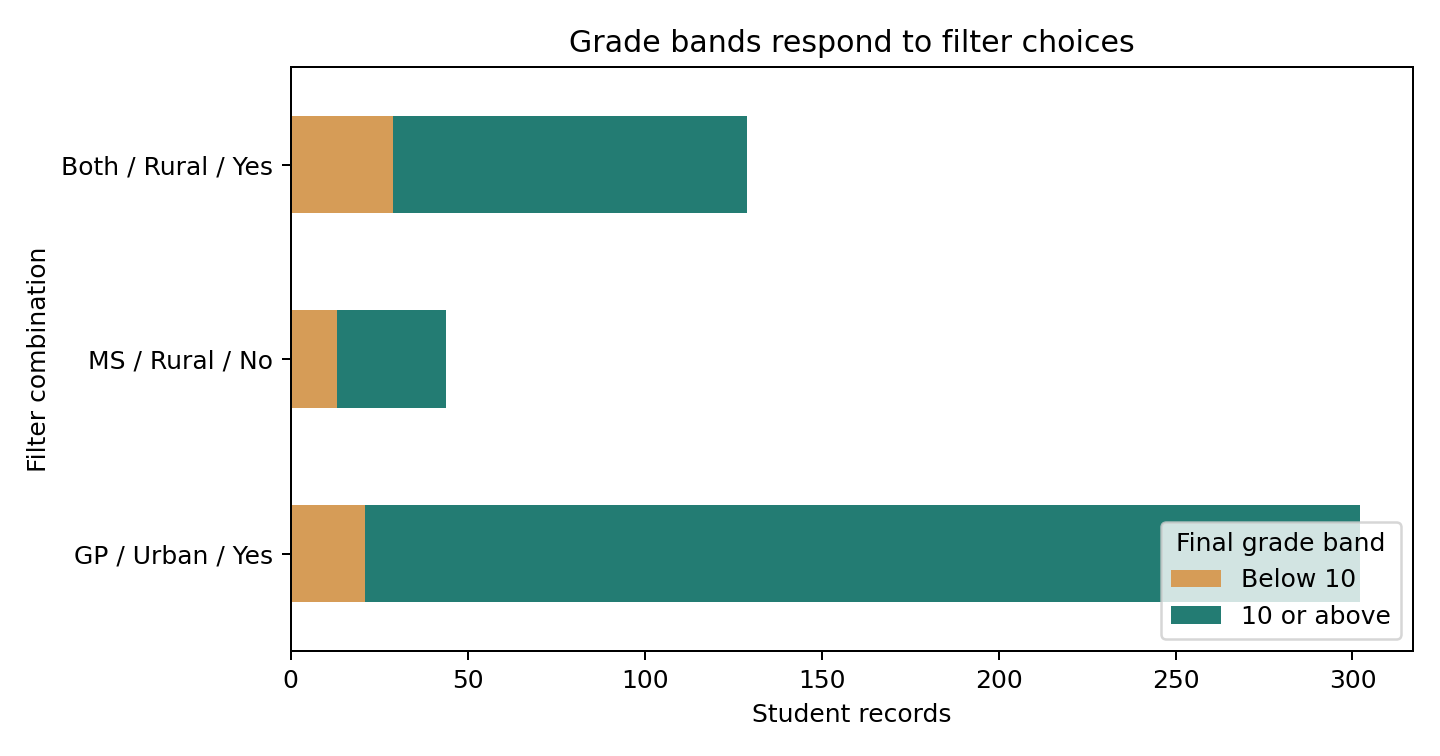

In [3]:
cases = {
 'GP / Urban / Yes': {'school':['gp'],'address':['u'],'internet':['yes']},
 'MS / Rural / No': {'school':['ms'],'address':['r'],'internet':['no']},
 'Both / Rural / Yes': {'school':['gp','ms'],'address':['r'],'internet':['yes']},
}
rows=[]
for name, selections in cases.items():
    subset=filter_data(df,selections)
    counts=grade_distribution(subset)
    assert counts.sum()==len(subset) and len(subset)>0
    rows.append({'filters':name,'records':len(subset),'mean_grade':subset.G3.mean(),**counts.to_dict()})
checks=pd.DataFrame(rows).set_index('filters')
assert checks.records.nunique()==3
display(checks.round(2))
checks.to_csv(OUT/'week4_filter_checks.csv')
ax=checks[LABELS].plot.barh(stacked=True,figsize=(8,4.2),color=['#D69C57','#237C73'])
ax.set(title='Grade bands respond to filter choices',xlabel='Student records',ylabel='Filter combination')
ax.legend(title='Final grade band',loc='lower right')
fig=ax.figure; fig.tight_layout();fig.savefig(OUT/'04_filter_validation.png',dpi=180);plt.close(fig)
from IPython.display import Image
display(Image(filename=str(OUT/'04_filter_validation.png')))

## 3. Prediction form examples
Use the existing Week 3 pipeline without refitting it on filtered data. Predictions are a learning demonstration, not guidance for individual students.

In [4]:
examples=[(1,3,4,'no','home-based'),(2,0,1,'yes','professional'),(4,0,2,'yes','services')]
rows=[]
for example in examples:
    category, probs=predict_grade(model,*example)
    assert category in LABELS and abs(sum(probs.values())-1)<1e-9
    rows.append(dict(zip(FEATURES,example))|{'prediction':category,**{f'probability_{k}':v for k,v in probs.items()}})
examples_df=pd.DataFrame(rows)
display(examples_df.round(3))
examples_df.to_csv(OUT/'week4_prediction_examples.csv',index=False)
print('Prediction examples verified.')

,studytime,failures,traveltime,internet,Mjob_group,prediction,probability_10 or above,probability_Below 10
0,1,3,4,no,home-based,Below 10,0.090,0.910
1,2,0,1,yes,professional,10 or above,0.933,0.067
2,4,0,2,yes,services,10 or above,0.978,0.022


Prediction examples verified.


## 4. Conclusion and limitations
The dashboard exposes interactive filtering and preserves the original Week 3 held-out results. The lowest study-time category has a lower mean grade in this sample, but the relationship is not causal. Logistic Regression has zero recall for below-10 students in the Week 3 test split, despite its apparently high accuracy. The model is not appropriate for student assessment or intervention. The sample contains two Portuguese schools and is not representative of all students. The three filter checks test the underlying calculations; interactive browser testing and recording a demo are separate manual tasks.